# Two-Model Link Surrogate Comparison

Evaluate **two trained MDN models** against **every** held-out SeQUeNCe test condition. For each condition and model we draw surrogate samples and score the fit with:

- **Wasserstein distance** (ms) - average displacement between the empirical distributions.
- **Normalized Wasserstein** - Wasserstein / mean service time, so conditions of different scale compare fairly.
- **KS statistic** - largest gap between the empirical CDFs (unitless, 0-1).

The notebook aggregates these across all conditions, then reports per-model summaries, a head-to-head win count, worst cases, and comparison plots.

In [4]:
from pathlib import Path
from time import perf_counter
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))


import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy.stats import ks_2samp, wasserstein_distance

from train_surrogate_link import FEATURE_NAMES, TIME_PATH, load_model, resolve_device, sample_from_model

# Two (or more) models to compare. Leave as None to auto-select every *.pt under hdf5/.
MODEL_PATHS = None
TEST_DIRECTORY = PROJECT_ROOT / "link/testing/h5"
SAMPLE_COUNT = 5000
SEED = 7

In [5]:
if MODEL_PATHS is None:
    MODEL_PATHS = sorted((PROJECT_ROOT / "hdf5").glob("*.pt"))
MODEL_PATHS = [Path(p) for p in MODEL_PATHS]
if len(MODEL_PATHS) < 2:
    raise ValueError(f"Need at least two models to compare; found {len(MODEL_PATHS)}")

test_paths = sorted(TEST_DIRECTORY.glob("*.h5"))
if not test_paths:
    raise FileNotFoundError(f"No HDF5 files found under {TEST_DIRECTORY}")

device = resolve_device("cuda" if torch.cuda.is_available() else "cpu")


def model_label(path):
    """Short, plot-friendly label taken from the model filename."""
    stem = path.stem
    if "nll=" in stem:
        return "nll=" + stem.split("nll=")[-1][:7]
    return stem


artifacts = {}
for path in MODEL_PATHS:
    artifact = load_model(path, device)
    label = model_label(path)
    artifacts[label] = artifact
    print(f"{label:<16} components={artifact['components']} "
          f"hidden_size={artifact['hidden_size']} hidden_layers={artifact['hidden_layers']}")

print(f"\nModels: {len(artifacts)} | Test conditions: {len(test_paths)} | Device: {device}")

nll=-0.7622      components=8 hidden_size=64 hidden_layers=2
nll=-1.0737      components=8 hidden_size=64 hidden_layers=2
nll=-1.6400      components=8 hidden_size=64 hidden_layers=2
nll=-1.6470      components=16 hidden_size=128 hidden_layers=4

Models: 4 | Test conditions: 80 | Device: cuda


## Evaluate every model on every test condition

One row per (model, condition). The five link features are stored alongside each score so we can later see *where* in feature space a model struggles.

In [6]:
def score(ground_truth, surrogate):
    """Distributional distance metrics between ground-truth and surrogate samples."""
    wasserstein_ms = wasserstein_distance(ground_truth, surrogate)
    ks = ks_2samp(ground_truth, surrogate)
    return {
        "wasserstein_ms": wasserstein_ms,
        "normalized_wasserstein": wasserstein_ms / float(np.mean(ground_truth)),
        "ks_statistic": float(ks.statistic),
        "ks_pvalue": float(ks.pvalue),
    }


records = []
start = perf_counter()
for test_index, test_path in enumerate(test_paths):
    with h5py.File(test_path, "r") as h5_file:
        attributes = h5_file["qnet/metadata/user_optional"].attrs
        parameters = {name: float(attributes[name]) for name in FEATURE_NAMES}
        ground_truth = np.asarray(h5_file[TIME_PATH][:], dtype=np.float32)

    for label, artifact in artifacts.items():
        surrogate = sample_from_model(artifact, parameters, SAMPLE_COUNT, SEED, device)
        records.append({
            "model": label,
            "condition": test_path.stem,
            "test_index": test_index,
            **parameters,
            "n_truth": int(ground_truth.size),
            "truth_mean_ms": float(np.mean(ground_truth)),
            **score(ground_truth, surrogate),
        })

elapsed = perf_counter() - start
results = pd.DataFrame.from_records(records)
print(f"Evaluated {len(test_paths)} conditions x {len(artifacts)} models in {elapsed:.1f} s")
results.head()

Evaluated 80 conditions x 4 models in 4.8 s


,model,condition,test_index,link_distance,memory_efficiency,detector_efficiency,attenuation,classical_delay_node,n_truth,truth_mean_ms,wasserstein_ms,normalized_wasserstein,ks_statistic,ks_pvalue
0,nll=-0.7622,linear_2_ld=10000_me=0.55_de=0.91_a=0.00025_cd...,0,10000.0,0.55,0.91,0.00025,0.025,5000,4.334748,0.154323,0.035601,0.0646,1.712864e-09
1,nll=-1.0737,linear_2_ld=10000_me=0.55_de=0.91_a=0.00025_cd...,0,10000.0,0.55,0.91,0.00025,0.025,5000,4.334748,0.200519,0.046258,0.0802,2.091329e-14
2,nll=-1.6400,linear_2_ld=10000_me=0.55_de=0.91_a=0.00025_cd...,0,10000.0,0.55,0.91,0.00025,0.025,5000,4.334748,0.216602,0.049969,0.0622,7.858993e-09
3,nll=-1.6470,linear_2_ld=10000_me=0.55_de=0.91_a=0.00025_cd...,0,10000.0,0.55,0.91,0.00025,0.025,5000,4.334748,0.209420,0.048312,0.0610,1.647298e-08
4,nll=-0.7622,linear_2_ld=10000_me=0.55_de=0.91_a=0.00025_cd...,1,10000.0,0.55,0.91,0.00025,0.077,5000,7.340056,0.470563,0.064109,0.0660,6.857486e-10


## Per-model summary across all conditions

In [7]:
metric_columns = ["wasserstein_ms", "normalized_wasserstein", "ks_statistic"]

summary_rows = []
for label, group in results.groupby("model"):
    for metric in metric_columns:
        series = group[metric]
        summary_rows.append({
            "model": label,
            "metric": metric,
            "mean": series.mean(),
            "median": series.median(),
            "p90": series.quantile(0.90),
            "max": series.max(),
        })
summary = pd.DataFrame(summary_rows)
summary

,model,metric,mean,median,p90,max
0,nll=-0.7622,wasserstein_ms,0.325496,0.176203,0.724434,2.204645
1,nll=-0.7622,normalized_wasserstein,0.051804,0.043096,0.086163,0.155615
2,nll=-0.7622,ks_statistic,0.085208,0.076200,0.132940,0.165200
3,nll=-1.0737,wasserstein_ms,0.257089,0.188041,0.513659,1.153602
4,nll=-1.0737,normalized_wasserstein,0.049206,0.040623,0.083190,0.147424
5,nll=-1.0737,ks_statistic,0.088090,0.080000,0.149820,0.173800
6,nll=-1.6400,wasserstein_ms,0.303351,0.268196,0.558015,0.992763
7,nll=-1.6400,normalized_wasserstein,0.052210,0.051661,0.062439,0.080035
8,nll=-1.6400,ks_statistic,0.087355,0.084100,0.132720,0.174000
9,nll=-1.6470,wasserstein_ms,0.299569,0.231304,0.612740,1.521688


## Head-to-head: which model wins per condition

Lower is better for both metrics. Counts how many test conditions each model fits better.

In [8]:
labels = list(artifacts.keys())
if len(labels) == 2:
    a, b = labels
    for metric in ["normalized_wasserstein", "ks_statistic"]:
        pivot = results.pivot(index="condition", columns="model", values=metric)
        a_wins = int((pivot[a] < pivot[b]).sum())
        b_wins = int((pivot[b] < pivot[a]).sum())
        ties = len(pivot) - a_wins - b_wins
        print(f"{metric}: '{a}' better on {a_wins}, '{b}' better on {b_wins}, "
              f"ties {ties} (of {len(pivot)} conditions)")
else:
    print(f"Head-to-head shown only for exactly two models; have {len(labels)}.")

Head-to-head shown only for exactly two models; have 4.


## Worst 5 conditions per model (by normalized Wasserstein)

In [9]:
worst = (results.sort_values("normalized_wasserstein", ascending=False)
         .groupby("model", group_keys=False).head(5)
         [["model", "condition", "normalized_wasserstein", "ks_statistic", "truth_mean_ms"]]
         .sort_values(["model", "normalized_wasserstein"], ascending=[True, False]))
worst

,model,condition,normalized_wasserstein,ks_statistic,truth_mean_ms
172,nll=-0.7622,linear_2_ld=18000_me=0.67_de=0.91_a=0.00033_cd...,0.155615,0.0936,14.167332
248,nll=-0.7622,linear_2_ld=2000_me=0.67_de=0.94_a=0.00033_cdn...,0.123644,0.1394,0.822561
188,nll=-0.7622,linear_2_ld=18000_me=0.67_de=0.94_a=0.00033_cd...,0.119513,0.0828,13.297443
232,nll=-0.7622,linear_2_ld=2000_me=0.67_de=0.91_a=0.00033_cdn...,0.105085,0.1386,0.884279
108,nll=-0.7622,linear_2_ld=14000_me=0.67_de=0.91_a=0.00033_cd...,0.091951,0.0740,9.236135
193,nll=-1.0737,linear_2_ld=2000_me=0.55_de=0.91_a=0.00025_cdn...,0.147424,0.1496,1.276453
249,nll=-1.0737,linear_2_ld=2000_me=0.67_de=0.94_a=0.00033_cdn...,0.134080,0.1546,0.822561
225,nll=-1.0737,linear_2_ld=2000_me=0.67_de=0.91_a=0.00025_cdn...,0.120117,0.1580,0.856612
209,nll=-1.0737,linear_2_ld=2000_me=0.55_de=0.94_a=0.00025_cdn...,0.119969,0.1346,1.193846
241,nll=-1.0737,linear_2_ld=2000_me=0.67_de=0.94_a=0.00025_cdn...,0.118861,0.1518,0.798731


## Metric distributions across conditions

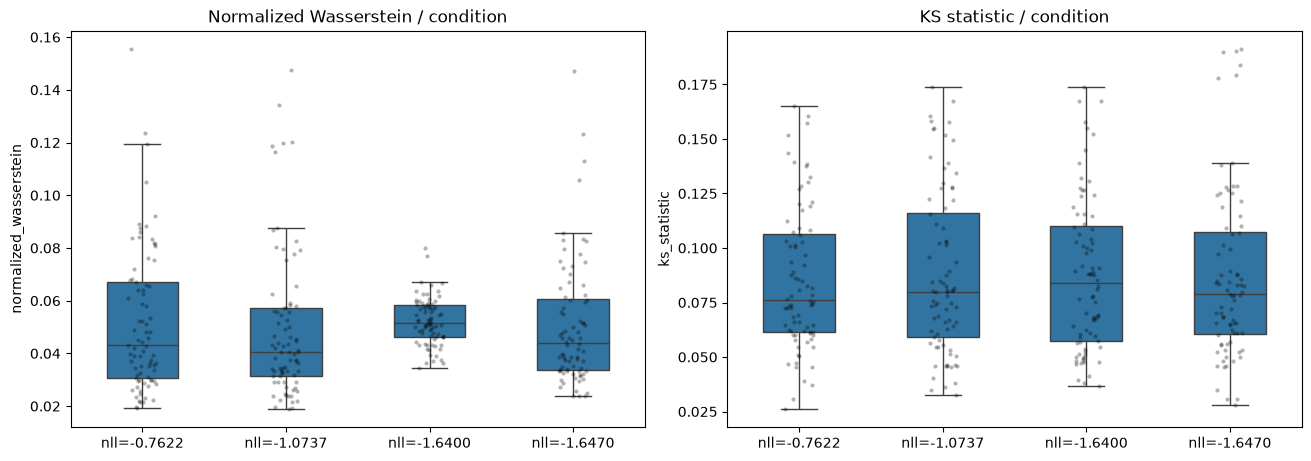

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, metric, title in zip(
        axes,
        ["normalized_wasserstein", "ks_statistic"],
        ["Normalized Wasserstein / condition", "KS statistic / condition"]):
    sns.boxplot(data=results, x="model", y=metric, ax=ax, width=0.5, showfliers=False)
    sns.stripplot(data=results, x="model", y=metric, ax=ax, color="black", alpha=0.3, size=3)
    ax.set_title(title)
    ax.set_xlabel("")
plt.show()

## Paired head-to-head scatter

Each point is one test condition. Points **below the diagonal** mean the model on the y-axis fits that condition better.

In [11]:
if len(labels) == 2:
    a, b = labels
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), constrained_layout=True)
    for ax, metric, title in zip(
            axes,
            ["normalized_wasserstein", "ks_statistic"],
            ["Normalized Wasserstein", "KS statistic"]):
        pivot = results.pivot(index="condition", columns="model", values=metric)
        lim = float(max(pivot[a].max(), pivot[b].max())) * 1.05
        ax.scatter(pivot[a], pivot[b], alpha=0.6)
        ax.plot([0, lim], [0, lim], "k--", linewidth=1)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_xlabel(a)
        ax.set_ylabel(b)
        ax.set_title(f"{title}\n(below line = '{b}' better)")
    plt.show()
else:
    print(f"Paired scatter shown only for exactly two models; have {len(labels)}.")

Paired scatter shown only for exactly two models; have 4.


## Where do the models struggle? (metric vs. features)

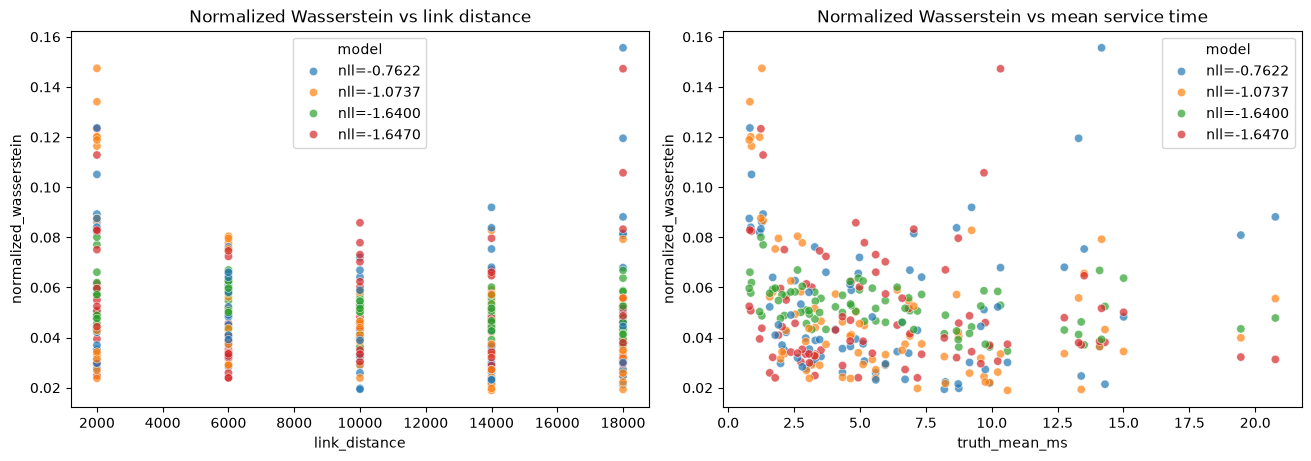

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
sns.scatterplot(data=results, x="link_distance", y="normalized_wasserstein",
                hue="model", ax=axes[0], alpha=0.7)
axes[0].set_title("Normalized Wasserstein vs link distance")
sns.scatterplot(data=results, x="truth_mean_ms", y="normalized_wasserstein",
                hue="model", ax=axes[1], alpha=0.7)
axes[1].set_title("Normalized Wasserstein vs mean service time")
plt.show()

## Save per-condition metrics

In [13]:
output_csv = (PROJECT_ROOT / "hdf5") / "two_model_evaluation.csv"
results.to_csv(output_csv, index=False)
print(f"Saved {len(results)} rows to {output_csv}")

Saved 320 rows to hdf5/two_model_evaluation.csv
